<a href="https://colab.research.google.com/github/JLettsSJU931/Machine-Learning-FA26/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 1:** Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.

Here I fetch the required data from openml into a raw dataset, then framing that dataset into a dataset. After this, I choose to clean up the table by giving the columns proper names to make the dataframe more legible.

In [26]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

# fetch dataset
diabetes_raw = fetch_openml(data_id=43582, as_frame=True, parser='auto')
df = diabetes_raw.frame
df.columns = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

# **Task 2:** Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.

As usual, I use .head(), .info(), and .describe() to show details about the dataframe. However, I also checked the data and noticed that it uses zeros to mask missing data, so I use .replace() to replace the zeros with nan values and proceed to display the amount of missing values in this step instead of the next one. Of course, I only change the values after putting them into a new dataframe, as to keep the original dataframe just in case.

In [27]:
print("Data Head")
display(df.head())
print('----------')
false_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
full_df = df
full_df[false_columns] = df[false_columns].replace(0, np.nan)
print('Before SimpleImputer:')
display(full_df.isna().sum())
print("--------------")
print("Data Info")
full_df.info()
print("--------------")
print("Data Description")
display(full_df.describe())

Data Head


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0,1.0
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0,0.0
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1.0


----------
Before SimpleImputer:


,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


--------------
Data Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    float64
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    float64
 8   Outcome                   768 non-null    float64
dtypes: float64(9)
memory usage: 54.1 KB
--------------
Data Description


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,763.000000,733.000000,541.000000,394.000000,757.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.535641,12.382158,10.476982,118.775855,6.924988,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,22.000000,76.250000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,36.000000,190.000000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


# **Task 3:** Quantify and handle implicit missing values using SimpleImputer.

This step is shortened from its usual state, as all I need to do here is create the simpleimputer and put the dataframe through it. So, that is what I do, and afterwards I display the fact that there are no more nan values.

In [28]:
from sklearn.impute import SimpleImputer

imp = SimpleImputer(missing_values=np.nan, strategy='median')
full_df[false_columns] = imp.fit_transform(full_df[false_columns])
print("After SimpleImputer:")
display(full_df.isna().sum())

After SimpleImputer:


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


# **Task 4:** Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

This step is done the exact same way as it has been done in previous assignments, so there is not much to say here that hasn't already been said.

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector

num_trans = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_trans = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
transformer = ColumnTransformer(transformers=[
    ("num", num_trans, make_column_selector(dtype_include=np.number)),
    ("cat", cat_trans, make_column_selector(dtype_include=["object", "category", "string", "bool"])),
])
true_df = transformer.fit_transform(full_df)

# **Task 5:** Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.

This step is the longest step by far code-wise. I first create x and y by putting all non target columns in x and the target column alone in y, along with creating the temp, test, train, and valid values to be used in training all the following models. I proceed to create a pipeline for all of the models mentioned in the task, and use them to create both the Hard and Soft Voting Classifiers. For both classifiers I transform the training data and make predictions for the data, as well as printing the accuracy scores and a classification report. Finally, I take the accuracy scores for both of the models and put them both on a bar graph to compare the values to visualize which model is more accurate.

Hard Voting
0.7886178861788617
Hard Accuracy Score
0.7987012987012987
Hard Classification report:
              precision    recall  f1-score   support

         0.0       0.81      0.91      0.85       100
         1.0       0.78      0.59      0.67        54

    accuracy                           0.80       154
   macro avg       0.79      0.75      0.76       154
weighted avg       0.80      0.80      0.79       154

--------------
Soft Voting
0.7723577235772358
Soft Accuracy Score
0.8116883116883117
Soft Classification report:
              precision    recall  f1-score   support

         0.0       0.81      0.93      0.87       100
         1.0       0.82      0.59      0.69        54

    accuracy                           0.81       154
   macro avg       0.81      0.76      0.78       154
weighted avg       0.81      0.81      0.80       154

--------------


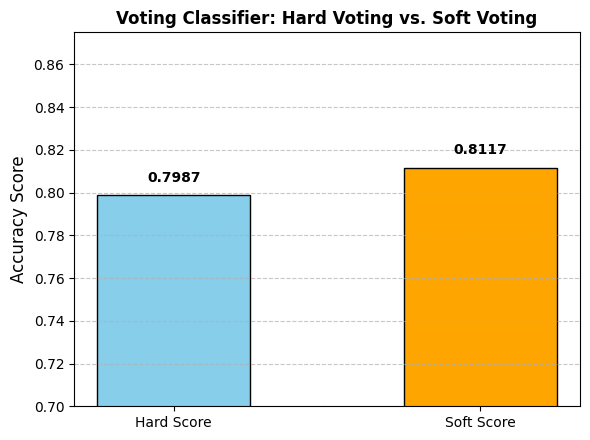

In [30]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

x = full_df.drop(columns=['Outcome'])
y = full_df['Outcome']
X_temp, X_test, y_temp, y_test = train_test_split(x, y, test_size=0.2, random_state=69, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(X_temp, y_temp, test_size=0.2, random_state=69, stratify=y_temp)

logreg_pipeline = Pipeline(steps=[
    ('transformer', transformer),
    ('logreg', LogisticRegression(random_state=69))
])
svc_pipeline = Pipeline(steps=[
    ('transformer', transformer),
    ('svc', SVC(C=1.0, kernel='rbf', probability=True, random_state=69))
])
dt_pipeline = Pipeline(steps=[
    ('transformer', transformer),
    ('dt', DecisionTreeClassifier(max_depth=3, random_state=69))
])

print("Hard Voting")
vote_hard = VotingClassifier(
    estimators=[
        ('lr', logreg_pipeline),
        ('svc', svc_pipeline),
        ('dt', dt_pipeline)
])
vote_hard.voting = "hard"
vote_hard.fit_transform(X_train, y_train)
y_pred_hard = vote_hard.predict(X_test)
print(vote_hard.score(X_valid, y_valid))
hard_accuracy = accuracy_score(y_test, y_pred_hard)
print('Hard Accuracy Score')
print(hard_accuracy)
print("Hard Classification report:")
print(classification_report(y_test, y_pred_hard))

print("--------------")
print("Soft Voting")
vote_soft = VotingClassifier(
    estimators=[
        ('lr', logreg_pipeline),
        ('svc', svc_pipeline),
        ('dt', dt_pipeline)
])
vote_soft.voting = "soft"
vote_soft.fit_transform(X_train, y_train)
y_pred_soft = vote_soft.predict(X_test)
print(vote_soft.score(X_valid, y_valid))
print('Soft Accuracy Score')
soft_accuracy = accuracy_score(y_test, y_pred_soft)
print(soft_accuracy)
print("Soft Classification report:")
print(classification_report(y_test, y_pred_soft))

print("--------------")

# Prepare data for plotting
metrics = ["Hard Score", "Soft Score"]
scores = [hard_accuracy, soft_accuracy]
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["skyblue", "orange"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Accuracy Score", fontsize=12)
plt.title(
    "Voting Classifier: Hard Voting vs. Soft Voting",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.70, 0.875)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()


# **Task 6:** Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.

Here I make a bagging classifier, making sure to enable the oob scores and bootstraping, as well as fiting the training data to this classifier. The predictions and test accuracty scores are taken, and another bar graph is created comparing the OOB score and the test accuracy.

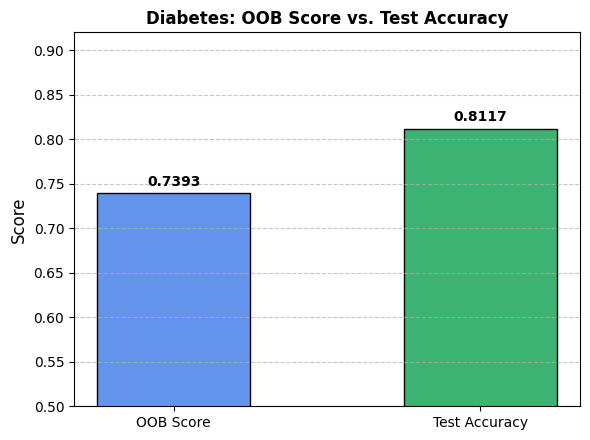

In [31]:
from sklearn.ensemble import BaggingClassifier

bag_toob = BaggingClassifier(DecisionTreeClassifier(), n_estimators=500,max_samples=100, bootstrap=True, oob_score=True, n_jobs=-1, random_state=69)
bag_toob.fit(X_train, y_train)
y_pred = bag_toob.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

# Prepare data for plotting
metrics = ["OOB Score", "Test Accuracy"]
scores = [bag_toob.oob_score_, test_accuracy]

# Create the bar plot
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["cornflowerblue", "mediumseagreen"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Score", fontsize=12)
plt.title(
    "Diabetes: OOB Score vs. Test Accuracy",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.50, 0.92)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

# **Task 7:** Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

First, I create a Random Forest classifier with feature subsetting configured with max_features="sqrt". Then the data is fit to the classifier and the predictions and accuracy scores are made. These scores are used to make a classification report to show its test performance. Finally, I generate a horizontal bar plot using feature importances taken using the column names in df.columns, showing which features affect the target value 'Outcome'.

Random Forest Test Accuracy: 0.7987

Classification Report:
              precision    recall  f1-score   support

         0.0       0.82      0.89      0.85       100
         1.0       0.76      0.63      0.69        54

    accuracy                           0.80       154
   macro avg       0.79      0.76      0.77       154
weighted avg       0.80      0.80      0.79       154



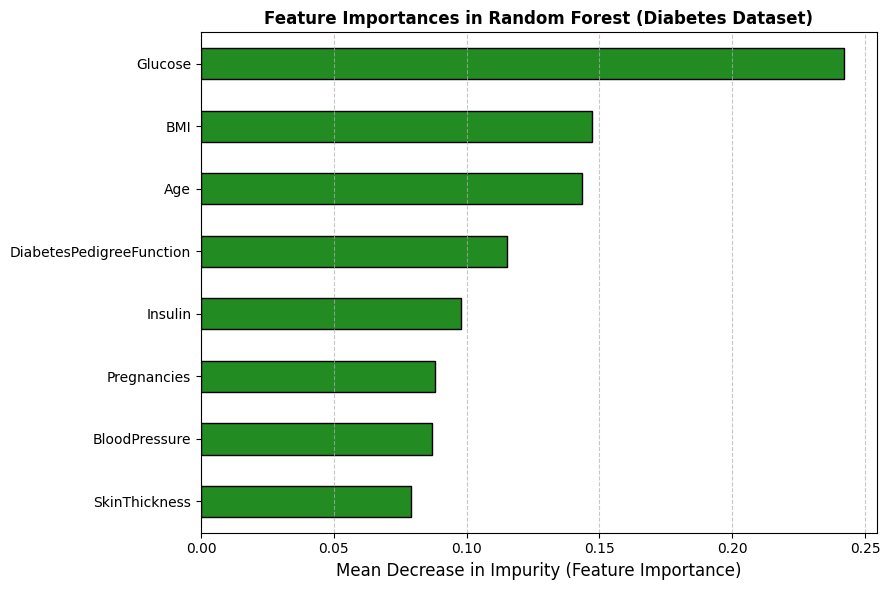

In [32]:
from sklearn.ensemble import RandomForestClassifier

rf_sub = RandomForestClassifier(n_estimators=500, max_features="sqrt", random_state=42, n_jobs=-1)
rf_sub.fit(X_train, y_train)
y_pred = rf_sub.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Test Accuracy: {test_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

importances = pd.Series(rf_sub.feature_importances_, index = df.columns.drop(['Outcome']))
importances_sorted = importances.sort_values(ascending=True)

plt.figure(figsize=(9, 6))
importances_sorted.plot(kind="barh", color="forestgreen", edgecolor="black")
plt.xlabel("Mean Decrease in Impurity (Feature Importance)", fontsize=12)
plt.title(
    "Feature Importances in Random Forest (Diabetes Dataset)",
    fontsize=12,
    fontweight="bold",
)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# **Task 8:** Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.

In this final task, I create the AdaBoost Classifier with a decsion stump of a max depth of 1, puting the training values through it to be fit. After this I take the accuracy scores of the training values and the testing values, ending the assignment with a final bar graph contrasting the two.

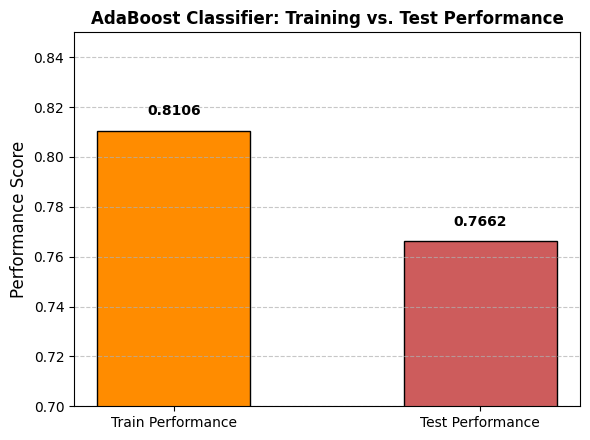

In [33]:
from sklearn.ensemble import AdaBoostClassifier

ada_stmp = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=69), n_estimators=200, learning_rate=1.0, random_state=69)
ada_stmp.fit(X_train, y_train)
train_perform = accuracy_score(y_train, ada_stmp.predict(X_train))
test_perform = accuracy_score(y_test, ada_stmp.predict(X_test))

# Prepare data for plotting
metrics = ["Train Performance", "Test Performance"]
scores = [train_perform, test_perform]

# Create the bar plot
plt.figure(figsize=(6, 4.5))
bars = plt.bar(
    metrics,
    scores,
    color=["darkorange", "indianred"],
    edgecolor="black",
    width=0.5,
)
plt.ylabel("Performance Score", fontsize=12)
plt.title(
    "AdaBoost Classifier: Training vs. Test Performance",
    fontsize=12,
    fontweight="bold",
)
plt.ylim(0.70, 0.85)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Annotate accuracy values on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()